In [2]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\Users\main\Desktop\Projects\RAG Based AI Assistant\.venv\Scripts\python.exe
Python version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


# 01 - Exploratory Data Analysis (EDA)

## Project: Enterprise IT RAG-Based AI Document Assistant

### Objective
The objective of this notebook is to explore and understand the
enterprise IT document dataset before performing data cleaning,
document preprocessing, text chunking, and vector embedding.

### Key Activities
1. Dataset inspection
2. Data structure and schema analysis
3. Missing value analysis
4. Duplicate document analysis
5. Document category analysis
6. Document quality assessment
7. Text length analysis
8. Data visualization
9. EDA findings and recommendations

In [3]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [16]:
visualization_dir = project_root / "reports" / "eda_report" / "visualizations"

visualization_dir.mkdir(parents=True, exist_ok=True)

print("Visualization folder:", visualization_dir)

Visualization folder: C:\Users\main\Desktop\Projects\RAG Based AI Assistant\reports\eda_report\visualizations


In [17]:

current_path = Path.cwd()

project_root = None

for path in [current_path, *current_path.parents]:
    if (path / "data" / "raw").exists():
        project_root = path
        break

if project_root is None:
    raise FileNotFoundError(
        "Project folder not found. Please check your notebook location."
    )

data_dir = project_root / "data" / "raw"

print("Project root:", project_root)
print("Raw data directory:", data_dir)


excel_files = list(data_dir.glob("*.xlsx"))

print("\nExcel files found:")

for file in excel_files:
    print(file.name)

Project root: C:\Users\main\Desktop\Projects\RAG Based AI Assistant
Raw data directory: C:\Users\main\Desktop\Projects\RAG Based AI Assistant\data\raw

Excel files found:
Enterprise_IT_RAG_Dataset.xlsx


In [18]:

if len(excel_files) == 0:
    raise FileNotFoundError("No Excel workbook found in data/raw.")

if len(excel_files) > 1:
    raise ValueError(
        "Multiple Excel files found. Select the correct dataset manually."
    )


file_path = excel_files[0]

excel_data = pd.ExcelFile(file_path)

print("Dataset:", file_path.name)
print("\nAvailable sheets:")

for sheet in excel_data.sheet_names:
    print("-", sheet)

Dataset: Enterprise_IT_RAG_Dataset.xlsx

Available sheets:
- Document_Corpus
- Query_Benchmark
- Data_Quality_Log
- Data_Dictionary
- README


In [19]:

df = pd.read_excel(
    file_path,
    sheet_name="Document_Corpus"
)

print("Document corpus loaded successfully!")
print("Dataset shape:", df.shape)

Document corpus loaded successfully!
Dataset shape: (84, 14)


In [20]:
df.head()

,document_id,title,category,department,owner,effective_date,review_date,version,status,source_system,access_level,document_text,quality_flags,expected_action
0,DOC-0001,Privileged Access Standard,Access Management,Security,Security Owner,2024-01-24,2025-01-23,1.1,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
1,DOC-0002,Privileged Access Standard - Working Copy 2,Access Management,Security,Security Owner,2024-02-02,2025-02-01,2.2,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
2,DOC-0003,Privileged Access Standard - Working Copy 3,Access Management,Security,Security Owner,2024-02-11,2025-02-10,3.0,Superseded,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
3,DOC-0004,Joiner-Mover-Leaver Procedure,Access Management,IT Operations,ITOperations Owner,2024-02-20,2025-02-19,1.1,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to it operations teams and authorized service owners. I...,none,retain
4,DOC-0005,Joiner-Mover-Leaver Procedure - Working Copy 2,Access Mgmt,IT Operations,ITOperations Owner,2024-02-29,2025-02-28,2.2,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to it operations teams and authorized service owners. I...,inconsistent_category,retain


In [21]:
df.columns.tolist()

['document_id',
 'title',
 'category',
 'department',
 'owner',
 'effective_date',
 'review_date',
 'version',
 'status',
 'source_system',
 'access_level',
 'document_text',
 'quality_flags',
 'expected_action']

In [22]:
print(f"Total documents: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

Total documents: 84
Total columns: 14


In [23]:
pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.values,
    "Non-Null Count": df.notnull().sum().values,
    "Missing Count": df.isnull().sum().values
})

,Column Name,Data Type,Non-Null Count,Missing Count
0,document_id,str,84,0
1,title,str,84,0
2,category,str,84,0
3,department,str,84,0
4,owner,str,77,7
5,effective_date,str,83,1
6,review_date,str,77,7
7,version,float64,82,2
8,status,str,84,0
9,source_system,str,84,0


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   document_id      84 non-null     str    
 1   title            84 non-null     str    
 2   category         84 non-null     str    
 3   department       84 non-null     str    
 4   owner            77 non-null     str    
 5   effective_date   83 non-null     str    
 6   review_date      77 non-null     str    
 7   version          82 non-null     float64
 8   status           84 non-null     str    
 9   source_system    84 non-null     str    
 10  access_level     84 non-null     str    
 11  document_text    84 non-null     str    
 12  quality_flags    84 non-null     str    
 13  expected_action  84 non-null     str    
dtypes: float64(1), str(13)
memory usage: 9.3 KB


In [25]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
document_id,84,84,DOC-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,84,82,Privileged Access Standard,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,84,19,Change Management,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,84,14,Security,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,77,19,Security Owner,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
effective_date,83,83,2024-01-24,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_date,77,77,2025-01-23,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
version,82.0,NaN,NaN,NaN,1.992683,0.8032,0.9,1.1,2.2,3.0,3.0
status,84,8,Approved,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_system,84,11,Controlled Knowledge Repository,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
sheet_summary = []

for sheet in excel_data.sheet_names:
    temp_df = pd.read_excel(file_path, sheet_name=sheet)

    sheet_summary.append({
        "Sheet Name": sheet,
        "Rows": temp_df.shape[0],
        "Columns": temp_df.shape[1]
    })

sheet_summary_df = pd.DataFrame(sheet_summary)

sheet_summary_df

,Sheet Name,Rows,Columns
0,Document_Corpus,84,14
1,Query_Benchmark,25,6
2,Data_Quality_Log,24,5
3,Data_Dictionary,14,3
4,README,12,2


In [27]:
category_counts = df["category"].value_counts()

category_counts

category
Change Management           10
End User Support            10
Incident Management          9
Service Levels               9
Network and Cloud            9
Data Protection              9
Access Management            8
Backup and Recovery          8
Access Mgmt                  2
SLA                          1
BCP / DR                     1
Data Governance              1
Incident Mgmt                1
Facilities                   1
Communications               1
Network & Infrastructure     1
Cloud Platform               1
Vendor Material              1
Backup & Recovery            1
Name: count, dtype: int64

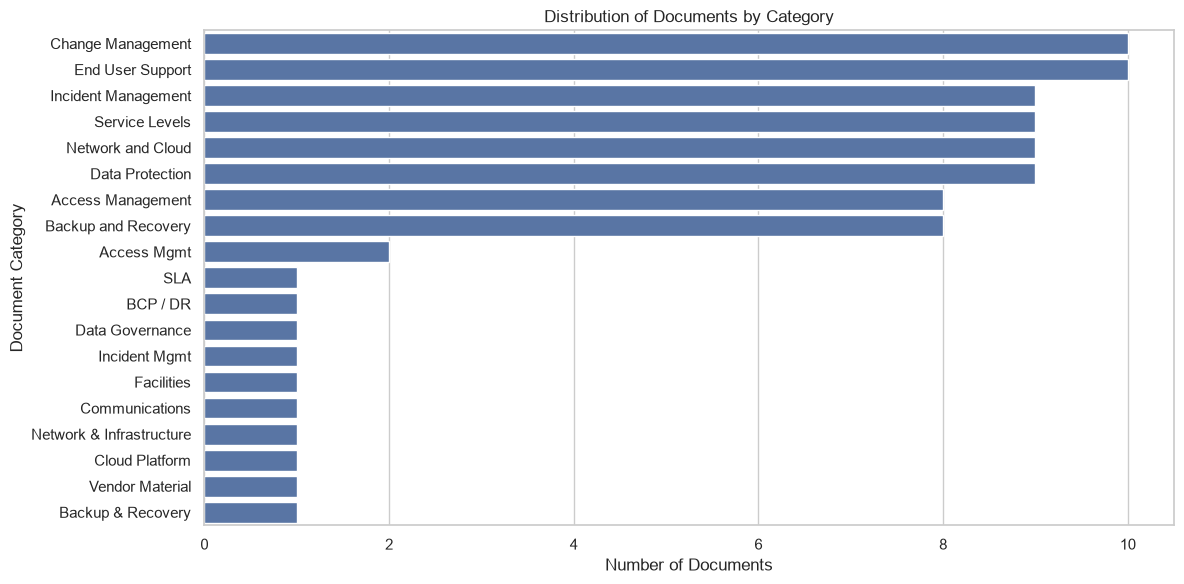

In [29]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index
)

plt.title("Distribution of Documents by Category")
plt.xlabel("Number of Documents")
plt.ylabel("Document Category")
plt.tight_layout()

plt.savefig(
    visualization_dir / "01_document_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
missing_analysis = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Available Values": df.notnull().sum()
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_analysis

,Missing Values,Missing Percentage,Available Values
owner,7,8.33,77
review_date,7,8.33,77
version,2,2.38,82
effective_date,1,1.19,83
title,0,0.00,84
document_id,0,0.00,84
category,0,0.00,84
department,0,0.00,84
status,0,0.00,84
source_system,0,0.00,84


In [31]:
missing_columns = missing_analysis[
    missing_analysis["Missing Values"] > 0
]

print("Total columns with missing values:", len(missing_columns))
print("\nColumns containing missing values:")

missing_columns

Total columns with missing values: 4

Columns containing missing values:


,Missing Values,Missing Percentage,Available Values
owner,7,8.33,77
review_date,7,8.33,77
version,2,2.38,82
effective_date,1,1.19,83


In [32]:
total_cells = df.size
total_missing = df.isnull().sum().sum()

overall_missing_percentage = (total_missing / total_cells) * 100

print("Total cells:", total_cells)
print("Total missing cells:", total_missing)
print("Overall missing percentage:", round(overall_missing_percentage, 2), "%")

Total cells: 1176
Total missing cells: 17
Overall missing percentage: 1.45 %


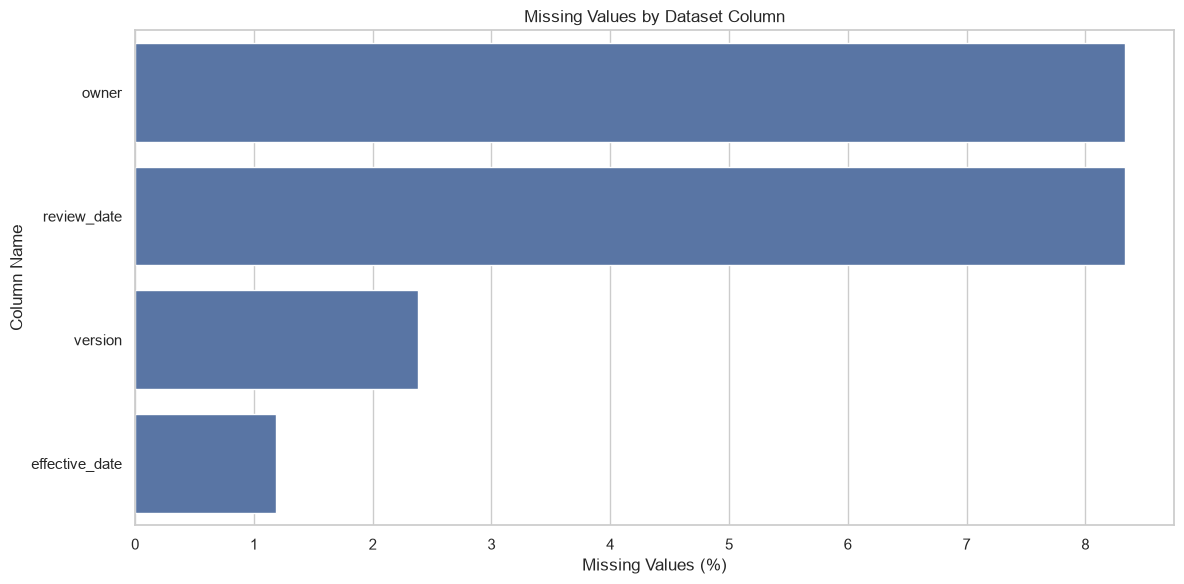

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_columns.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.title("Missing Values by Dataset Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Name")
plt.tight_layout()

plt.savefig(
    visualization_dir / "02_missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
missing_records = df[df.isnull().any(axis=1)]

print("Total records with missing values:", len(missing_records))

missing_records

Total records with missing values: 12


,document_id,title,category,department,owner,effective_date,review_date,version,status,source_system,access_level,document_text,quality_flags,expected_action
7,DOC-0008,Service Account Governance - Working Copy 2,Access Management,Security,NaN,2024-03-27,2025-03-27,2.2,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,missing_owner,retain
11,DOC-0012,Incident Priority and Escalation Matrix - Working Copy 3,Incident Management,IT Service Desk,ITServiceDesk Owner,2024-05-02,NaN,3.0,Superseded,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to it service desk teams and authorized service owners....,missing_review_date,retain
26,DOC-0027,Vendor Support Escalation Guide - Working Copy 3,Service Levels,Vendor Management,NaN,2024-09-14,2025-09-14,3.0,Superseded,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to vendor management teams and authorized service owner...,missing_owner,retain
34,DOC-0035,Change Freeze Calendar Guidance - Working Copy 2,Change Management,Application Support,ApplicationSupport Owner,2024-11-25,NaN,2.2,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to application support teams and authorized service own...,missing_review_date,retain
45,DOC-0046,Cloud Resource Provisioning Standard,Network and Cloud,Cloud Platform,NaN,2025-03-04,2026-03-04,1.1,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to cloud platform teams and authorized service owners. ...,missing_owner,retain
57,DOC-0058,Secure File Transfer Procedure,Data Protection,Security,Security Owner,2025-06-20,NaN,1.1,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,missing_review_date,retain
64,DOC-0065,Managed Laptop Troubleshooting Guide - Working Copy 2,End User Support,IT Service Desk,NaN,2025-08-22,2026-08-22,2.2,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to it service desk teams and authorized service owners....,missing_owner,retain
72,DOC-X001,Privileged Access Standard,Access Mgmt,IT Ops,NaN,NaN,NaN,NaN,Active,SharePoint export,Internal,Privileged access can be granted by any team member without manager or security approval. This s...,inaccurate_content; inconsistent_category; missing_owner; missing_dates; missing_version; mislea...,quarantine
78,DOC-X007,Cloud Resource Provisioning Standard,Cloud Platform,Cloud Platform,Cloud Owner,2025-07-01,NaN,2.1,Approved,Cloud Wiki,Internal,"Cloud resources must use approved landing zones, identity controls, encryption, logging, tagging...",missing_review_date; partial_content,retain_with_metadata_warning
79,DOC-X008,Password reset quick note,End User Support,IT Service Desk,NaN,2025-08-01,NaN,NaN,Published,Ticket comment,Internal,"If a user cannot sign in, verify identity using the approved process and follow the identity pla...",missing_owner; missing_review_date; missing_version; weak_provenance,retain_with_warning


In [35]:
missing_records_summary = df.isnull().sum(axis=1).value_counts().sort_index()

missing_records_summary

0    72
1    10
3     1
4     1
Name: count, dtype: int64

In [36]:
exact_duplicates = df[df.duplicated(keep=False)]

print("Total duplicate records:", len(exact_duplicates))
exact_duplicates

Total duplicate records: 0


,document_id,title,category,department,owner,effective_date,review_date,version,status,source_system,access_level,document_text,quality_flags,expected_action


In [37]:
duplicate_ids = df[
    df["document_id"].duplicated(keep=False)
].sort_values("document_id")

print("Records with duplicate document IDs:", len(duplicate_ids))

duplicate_ids

Records with duplicate document IDs: 0


,document_id,title,category,department,owner,effective_date,review_date,version,status,source_system,access_level,document_text,quality_flags,expected_action


In [38]:
duplicate_titles = df[
    df["title"].duplicated(keep=False)
].sort_values("title")

print("Records with duplicate titles:", len(duplicate_titles))

duplicate_titles

Records with duplicate titles: 4


,document_id,title,category,department,owner,effective_date,review_date,version,status,source_system,access_level,document_text,quality_flags,expected_action
45,DOC-0046,Cloud Resource Provisioning Standard,Network and Cloud,Cloud Platform,NaN,2025-03-04,2026-03-04,1.1,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to cloud platform teams and authorized service owners. ...,missing_owner,retain
78,DOC-X007,Cloud Resource Provisioning Standard,Cloud Platform,Cloud Platform,Cloud Owner,2025-07-01,NaN,2.1,Approved,Cloud Wiki,Internal,"Cloud resources must use approved landing zones, identity controls, encryption, logging, tagging...",missing_review_date; partial_content,retain_with_metadata_warning
0,DOC-0001,Privileged Access Standard,Access Management,Security,Security Owner,2024-01-24,2025-01-23,1.1,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
72,DOC-X001,Privileged Access Standard,Access Mgmt,IT Ops,NaN,NaN,NaN,NaN,Active,SharePoint export,Internal,Privileged access can be granted by any team member without manager or security approval. This s...,inaccurate_content; inconsistent_category; missing_owner; missing_dates; missing_version; mislea...,quarantine


In [39]:
title_duplicate_summary = (
    df.groupby("title")
    .size()
    .reset_index(name="Document Count")
    .query("`Document Count` > 1")
    .sort_values("Document Count", ascending=False)
)

title_duplicate_summary

,title,Document Count
9,Cloud Resource Provisioning Standard,2
56,Privileged Access Standard,2


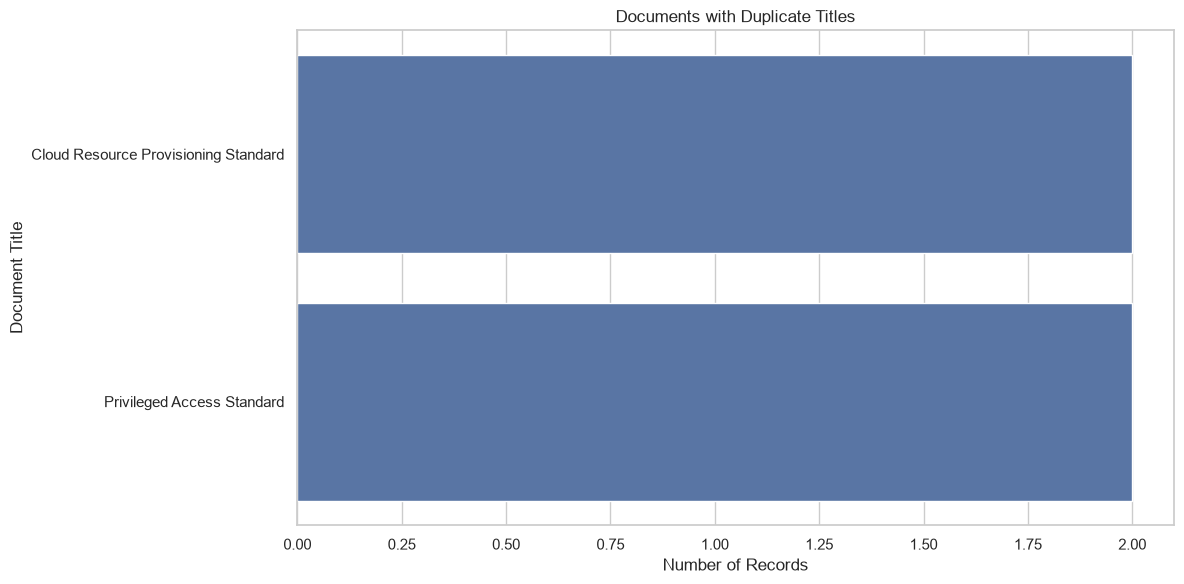

In [40]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=title_duplicate_summary,
    x="Document Count",
    y="title"
)

plt.title("Documents with Duplicate Titles")
plt.xlabel("Number of Records")
plt.ylabel("Document Title")
plt.tight_layout()

plt.savefig(
    visualization_dir / "03_duplicate_title_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
from difflib import SequenceMatcher

In [42]:
unique_titles = df["title"].dropna().unique()

similar_titles = []

for i in range(len(unique_titles)):
    for j in range(i + 1, len(unique_titles)):
        similarity = SequenceMatcher(
            None,
            str(unique_titles[i]).lower(),
            str(unique_titles[j]).lower()
        ).ratio()

        if similarity >= 0.75:
            similar_titles.append({
                "Title 1": unique_titles[i],
                "Title 2": unique_titles[j],
                "Similarity Score": round(similarity, 3)
            })

similar_titles_df = pd.DataFrame(similar_titles)

similar_titles_df.sort_values(
    "Similarity Score",
    ascending=False
)

,Title 1,Title 2,Similarity Score
25,Critical Application Support Agreement - Working Copy 2,Critical Application Support Agreement - Working Copy 3,0.982
12,Incident Priority and Escalation Matrix - Working Copy 2,Incident Priority and Escalation Matrix - Working Copy 3,0.982
56,Data Classification and Handling Policy - Working Copy 2,Data Classification and Handling Policy - Working Copy 3,0.982
31,Production Change Management Policy - Working Copy 2,Production Change Management Policy - Working Copy 3,0.981
65,Managed Laptop Troubleshooting Guide - Working Copy 2,Managed Laptop Troubleshooting Guide - Working Copy 3,0.981
...,...,...,...
6,Service Account Governance,Service Account Governance - Working Copy 2,0.754
32,Emergency Change Procedure,Emergency Change Procedure - Working Copy 2,0.754
33,Emergency Change Procedure,Emergency Change Procedure - Working Copy 3,0.754
38,Backup Operations Standard,Backup Operations Standard - Working Copy 2,0.754


In [43]:
df.columns.tolist()

['document_id',
 'title',
 'category',
 'department',
 'owner',
 'effective_date',
 'review_date',
 'version',
 'status',
 'source_system',
 'access_level',
 'document_text',
 'quality_flags',
 'expected_action']

In [44]:
df["status"].value_counts(dropna=False)

status
Approved      27
Draft         25
Superseded    24
Expired        3
Published      2
approved       1
Active         1
Archived       1
Name: count, dtype: int64

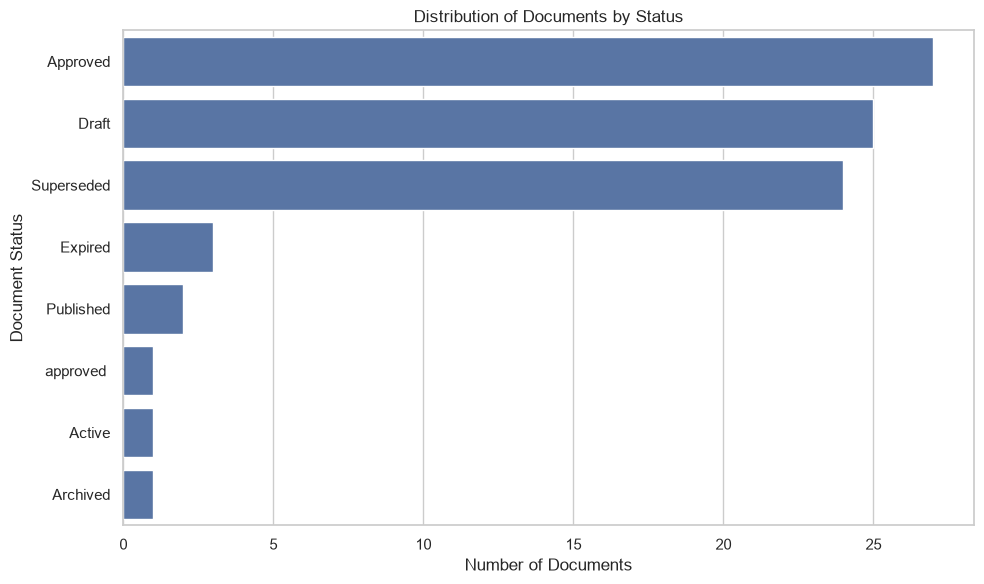

In [45]:
status_counts = df["status"].value_counts(dropna=False).reset_index()

status_counts.columns = ["Status", "Document Count"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=status_counts,
    x="Document Count",
    y="Status"
)

plt.title("Distribution of Documents by Status")
plt.xlabel("Number of Documents")
plt.ylabel("Document Status")
plt.tight_layout()

plt.savefig(
    visualization_dir / "04_document_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
df["version"].value_counts(dropna=False).sort_index()

version
0.9     1
1.0     6
1.1    24
1.2     1
2.0     1
2.1     1
2.2    24
3.0    24
NaN     2
Name: count, dtype: int64

In [47]:
df.select_dtypes(include=["object", "datetime"]).head()

C:\Users\main\AppData\Local\Temp\ipykernel_14352\2995916145.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=["object", "datetime"]).head()


,document_id,title,category,department,owner,effective_date,review_date,status,source_system,access_level,document_text,quality_flags,expected_action
0,DOC-0001,Privileged Access Standard,Access Management,Security,Security Owner,2024-01-24,2025-01-23,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
1,DOC-0002,Privileged Access Standard - Working Copy 2,Access Management,Security,Security Owner,2024-02-02,2025-02-01,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
2,DOC-0003,Privileged Access Standard - Working Copy 3,Access Management,Security,Security Owner,2024-02-11,2025-02-10,Superseded,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to security teams and authorized service owners. It des...,none,retain
3,DOC-0004,Joiner-Mover-Leaver Procedure,Access Management,IT Operations,ITOperations Owner,2024-02-20,2025-02-19,Approved,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to it operations teams and authorized service owners. I...,none,retain
4,DOC-0005,Joiner-Mover-Leaver Procedure - Working Copy 2,Access Mgmt,IT Operations,ITOperations Owner,2024-02-29,2025-02-28,Draft,Controlled Knowledge Repository,Internal,Purpose and scope: This document applies to it operations teams and authorized service owners. I...,inconsistent_category,retain


In [49]:
df["review_date"] = pd.to_datetime(
    df["review_date"],
    errors="coerce"
)

df["review_date"].describe()

count                     77
mean     2025-11-09 00:00:00
min      2022-02-01 00:00:00
25%      2025-06-25 00:00:00
50%      2025-12-13 00:00:00
75%      2026-05-15 00:00:00
max      2026-10-24 00:00:00
Name: review_date, dtype: object

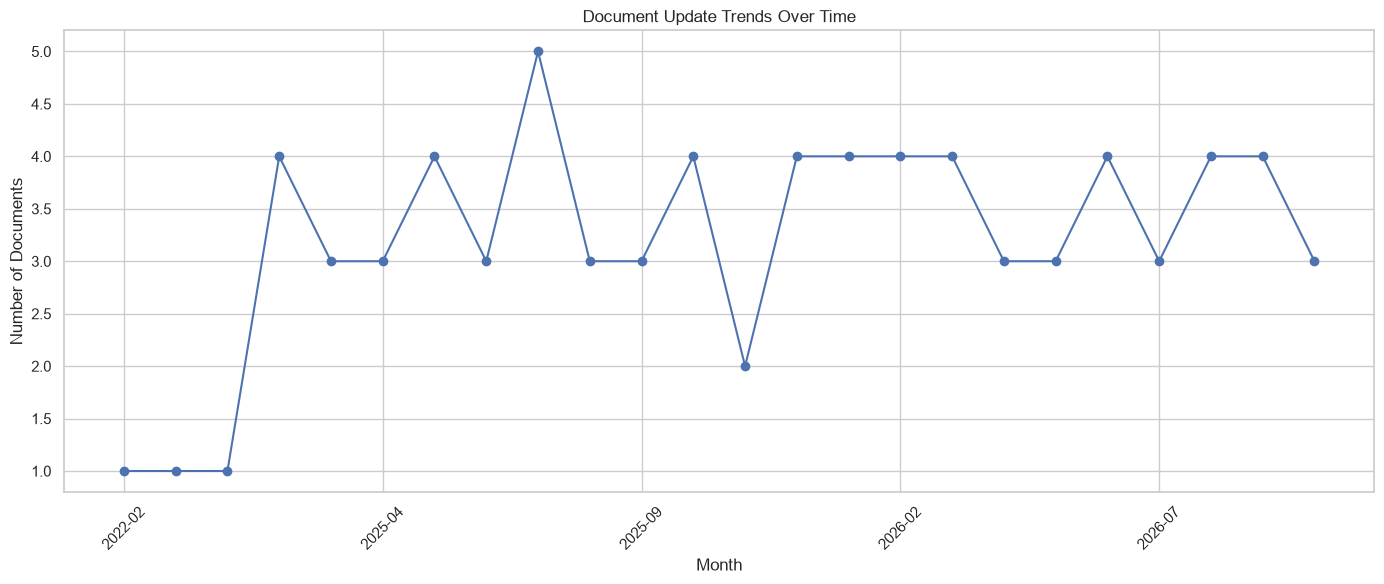

In [51]:
date_counts = (
    df.dropna(subset=["review_date"])
    .groupby(df["review_date"].dt.to_period("M"))
    .size()
)

date_counts.index = date_counts.index.astype(str)

plt.figure(figsize=(14, 6))

date_counts.plot(kind="line", marker="o")

plt.title("Document Update Trends Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    visualization_dir / "05_document_update_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()